# NB02 · Merton structural model

**Project:** multiyear-credit-engine
**Job requirement covered:** Merton-approach model; Merton models (required skills).
**Engine module:** `creditengine.models.merton`
**Assumptions:** A-12
**Theory:** Bluhm §3.3–3.4
**Status:** ✅ Developed — every function is built from scratch in this notebook

## Objective

From a firm's stock price and balance sheet, what is its one-year probability of default, and do these market-implied PDs rank firms the same way their ratings do?

## Results at a glance

| Question | Answer |
|---|---|
| Ford's one-year PD from market data | **0.15%** (distance to default 2.97); rating-implied BBB: 0.14% |
| How much do modelling choices move it? | Solver: 0.15% → 0.33%. Default-point rule: 0.08% → 0.20% |
| Do market and ratings rank the 15 issuers alike? | Yes — Spearman rank correlation **0.91** |
| How did it behave in the 2020 crash? | Every issuer's DD fell; cruise line CCL went from 7.5 to 0.9 in three months |
| Did every solve work? | Yes — 15 issuers today and all 540 firm-months 2019–2021 |

## Notation

| Symbol | Meaning | Unit / source |
|---|---|---|
| $V$ | Market value of the firm's assets — **not observed** | USD |
| $\sigma_V$ | Annual volatility of asset value — **not observed** | decimal (0.08 = 8%) |
| $E$ | Market value of equity = share price × shares outstanding | USD; prices + SEC filings |
| $\sigma_E$ | Annual volatility of equity, from the last 252 daily returns | decimal |
| $D$ | Default point = current liabilities + ½ non-current liabilities | USD; SEC 10-K / 10-Q |
| $r$ | Risk-free rate = 1-year US Treasury yield | decimal; FRED `DGS1` |
| $\mu$ | Expected growth rate of assets; set equal to $r$ here | decimal |
| $T$ | Horizon | 1 year |
| $N(\cdot)$ | Standard normal cumulative distribution | — |
| $DD$ | Distance to default: how many standard deviations the assets sit above $D$ | number |
| $PD$ | Probability of default within one year $= N(-DD)$ | % |

Assumption IDs (A-01, A-12) refer to `docs/assumption_register.md`. **KMV** is Moody's KMV, the industry version of the Merton model.

## Inputs

| Data | File | Used for |
|---|---|---|
| SEC company facts (balance sheet, shares) | `data/raw/sec_edgar/companyfacts/<TICKER>.json` | $D$ and share count |
| Daily share prices | `data/raw/market/prices/<TICKER>.csv` (local only) | $E$ and $\sigma_E$ |
| 1-year Treasury yield | `data/raw/fred/rates/DGS1.csv` | $r$ |
| US recession flag (NBER) | `data/raw/fred/macro/USREC.csv` | shading in the 2020 chart |
| S&P one-year transition matrix | `data/external/transition_matrix_1y.csv` (local only) | rating-implied PD |

## Outputs

- `data/processed/merton_dd_panel.parquet` — monthly inputs, DD and PD for 15 issuers, 2019–2021
- `reports/figures/merton_dd_vs_rating.png` — distance to default against agency rating
- `reports/figures/merton_dd_2020.png` — distance to default through the 2020 crash

## 0. Setup

Libraries, file paths and the two fixed settings (horizon and volatility window). Nothing is random, so results are exactly repeatable.

### 0.1 Imports and paths

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq, fsolve
from scipy.stats import norm, spearmanr

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"

T = 1.0        # horizon in years (A-12)
WINDOW = 252   # trading days for equity volatility (A-12)
pd.set_option("display.float_format", "{:,.3f}".format)

print(DATA.exists(), DATA)

True C:\Users\siava\OneDrive\Desktop\portfolio_risk_management\multiyear-credit-engine\data


### 0.2 Issuer universe

15 listed US issuers spread from AAA to B+, so the rating comparison in section 5 has a real range. Ratings are indicative (see `data/raw/MANIFEST.md`).

In [2]:
# Starter universe from data/raw/MANIFEST.md (issuer ratings indicative only)
UNIVERSE = {"MSFT": "AAA", "JNJ": "AAA", "AAPL": "AA+", "XOM": "AA-", "NFLX": "A",
            "T": "BBB", "KHC": "BBB", "F": "BBB-", "BA": "BBB-", "OXY": "BBB-",
            "HCA": "BBB-", "DAL": "BBB-", "CCL": "BB+", "M": "BB+", "AAL": "B+"}
FACTS_FILE = {"XOM": "XOM_CIK0000034088"}   # legacy Exxon Mobil filings (see MANIFEST)
EXAMPLE = "F"                               # worked firm for sections 2-4

pd.Series(UNIVERSE).value_counts()

BBB-    5
AAA     2
BBB     2
BB+     2
A       1
AA-     1
AA+     1
B+      1
Name: count, dtype: int64

## 1. Theory: equity as a call on firm assets

**Idea in one line:** shareholders own the firm's assets but must repay the debt first, so their stake behaves like a call option on the assets.

$$V_T = V_0\,\exp\big((\mu - \tfrac12\sigma_V^2)T + \sigma_V\sqrt{T}\,Z\big)$$

Asset value moves randomly over the year, like a stock price ($Z$ is a standard normal shock).

$$E_T = \max(V_T - D,\ 0)$$

At the horizon shareholders get whatever is left after paying $D$ — or nothing. That is a call option with strike $D$.

$$E = V\,N(d_1) - D\,e^{-rT}N(d_2), \qquad d_1 = \frac{\ln(V/D) + (r + \tfrac12\sigma_V^2)T}{\sigma_V\sqrt{T}}, \qquad d_2 = d_1 - \sigma_V\sqrt{T}$$

Black–Scholes gives today's value of that option.

$$\sigma_E\,E = N(d_1)\,\sigma_V\,V$$

Equity is a thin slice on top of the debt, so it is much more volatile than the assets.

**The problem to solve:** we can see $E$, $\sigma_E$, $D$ and $r$ in the market and the filings, but not $V$ and $\sigma_V$. The last two equations give two equations in those two unknowns — section 3 solves them.

### 1.1 Black–Scholes equity from assets

In [3]:
def equity_from_assets(V, sigma_v, D, r, T=1.0):
    # Black-Scholes equity value and equity volatility implied by assets (V, sigma_V)
    d1 = (np.log(V / D) + (r + 0.5 * sigma_v**2) * T) / (sigma_v * np.sqrt(T))
    d2 = d1 - sigma_v * np.sqrt(T)
    E = V * norm.cdf(d1) - D * np.exp(-r * T) * norm.cdf(d2)
    sigma_e = V / E * norm.cdf(d1) * sigma_v
    return E, sigma_e

E_toy, se_toy = equity_from_assets(V=100, sigma_v=0.20, D=80, r=0.04)
print(f"V = 100, D = 80, sigma_V = 20%  ->  E = {E_toy:.2f}, sigma_E = {se_toy:.1%}")

V = 100, D = 80, sigma_V = 20%  ->  E = 23.91, sigma_E = 77.1%


**Reading the result:** a firm whose assets move 20% a year has equity that moves about 77% a year, because equity is only about 24 on top of 80 of debt. Equity volatility therefore overstates the risk of the firm itself.

## 2. Build inputs: debt default point, equity value, equity volatility

The four things the model needs, built from public data for the worked firm, **Ford (F)**.

$$D = \text{current liabilities} + \tfrac12 \times \text{non-current liabilities}$$

Default point (KMV rule, A-12): debt due within a year counts in full, longer-term debt only by half.

$$E = \text{share price} \times \text{shares outstanding}$$

What the market says the equity is worth today.

$$\sigma_E = \text{stdev}\big(\ln P_t - \ln P_{t-1}\big) \times \sqrt{252}$$

Daily price moves over the last year, scaled to one year.

$$r = \text{1-year Treasury yield}$$

Risk-free rate matched to the 1-year horizon.

**Why Ford:** its balance sheet includes Ford Credit, a large lending business, so its default point is big relative to its equity — a demanding first case.

### 2.1 Load daily prices

In [4]:
def load_prices(ticker):
    # Daily closing prices, indexed by date
    path = DATA / "raw" / "market" / "prices" / f"{ticker}.csv"
    frame = pd.read_csv(path, parse_dates=["date"])
    return frame.set_index("date")["close"].dropna()

prices = load_prices(EXAMPLE)
print(f"{EXAMPLE}: {len(prices)} days, {prices.index[0].date()} to {prices.index[-1].date()}")
prices.tail(3)

F: 5477 days, 2005-01-03 to 2026-10-09


date
2026-10-07   12.120
2026-10-08   12.250
2026-10-09   12.170
Name: close, dtype: float64

### 2.2 Load balance sheet and shares (SEC)

SEC "company facts" files hold every number a firm has reported in its 10-K and 10-Q filings. `latest_fact` picks the most recent value of one item.

In [5]:
def load_facts(ticker):
    # SEC XBRL company facts (balance sheet, shares) for one issuer
    name = FACTS_FILE.get(ticker, ticker)
    path = DATA / "raw" / "sec_edgar" / "companyfacts" / f"{name}.json"
    with open(path, encoding="utf-8") as fh:
        return json.load(fh)

def latest_fact(facts, tag, taxonomy="us-gaap", unit="USD"):
    # Most recent value of one tag from a 10-K or 10-Q, and its period-end date
    items = facts["facts"].get(taxonomy, {}).get(tag, {}).get("units", {}).get(unit, [])
    items = [i for i in items if i.get("form") in ("10-K", "10-Q")]
    if not items:
        return np.nan, None
    best = max(items, key=lambda i: (i["end"], i.get("filed", "")))
    return float(best["val"]), best["end"]

facts = load_facts(EXAMPLE)
pd.DataFrame({
    "shares": latest_fact(facts, "EntityCommonStockSharesOutstanding", "dei", "shares"),
    "total liabilities": latest_fact(facts, "Liabilities"),
    "current liabilities": latest_fact(facts, "LiabilitiesCurrent"),
}, index=["value", "period end"]).T

,value,period end
shares,"3,727,332,952.000",2011-04-28
total liabilities,"244,950,000,000.000",2026-03-31
current liabilities,"106,679,000,000.000",2026-03-31


**Data issue found:** liabilities are current (2026), but the cover-page share count stops in **2011**. Ford reports its two share classes separately since then, and the SEC file drops per-class values. Using it would misstate equity — fixed in 2.3.

### 2.3 Shares outstanding (most recent across tags)

Check three places a share count can be reported and keep the newest, so one stale item cannot drive $E$.

In [6]:
SHARE_TAGS = [("dei", "EntityCommonStockSharesOutstanding"),       # cover page
              ("us-gaap", "CommonStockSharesOutstanding"),          # balance sheet
              ("us-gaap", "WeightedAverageNumberOfSharesOutstandingBasic")]  # EPS note, every quarter

def shares_outstanding(facts):
    # Most recent share count across tags, so one stale tag cannot drive E
    found = [latest_fact(facts, tag, tax, "shares") for tax, tag in SHARE_TAGS]
    found = [(v, end) for v, end in found if end is not None]
    return max(found, key=lambda x: x[1])

pd.DataFrame([latest_fact(facts, tag, tax, "shares") for tax, tag in SHARE_TAGS],
             index=[tag for _, tag in SHARE_TAGS], columns=["shares", "period end"])

,shares,period end
EntityCommonStockSharesOutstanding,"3,727,332,952.000",2011-04-28
CommonStockSharesOutstanding,NaN,None
WeightedAverageNumberOfSharesOutstandingBasic,"3,991,000,000.000",2026-03-31


**Reading the result:** the earnings-per-share count gives 3.99bn shares at March 2026, replacing the 2011 figure.

### 2.4 Load the 1-year Treasury rate (FRED)

In [7]:
def load_fred(folder, series):
    # One FRED series as floats indexed by date ('.' = missing day)
    frame = pd.read_csv(DATA / "raw" / "fred" / folder / f"{series}.csv")
    values = pd.to_numeric(frame[series], errors="coerce")
    return pd.Series(values.to_numpy(), index=pd.to_datetime(frame["observation_date"]), name=series).dropna()

rates = load_fred("rates", "DGS1")
print(f"DGS1: {rates.index[0].date()} to {rates.index[-1].date()}, latest {rates.iloc[-1]:.2f}%")

DGS1: 1962-01-02 to 2026-10-08, latest 4.44%


### 2.5 Merton inputs for Ford: $D$, $E$, $\sigma_E$, $r$

In [8]:
cur, bs_date = latest_fact(facts, "LiabilitiesCurrent")
tot, _ = latest_fact(facts, "Liabilities")
shares, _ = shares_outstanding(facts)

D = cur + 0.5 * (tot - cur)                              # KMV default point
E = prices.iloc[-1] * shares                             # market value of equity
log_ret = np.log(prices).diff().dropna().iloc[-WINDOW:]  # last 252 daily log returns
sigma_E = log_ret.std(ddof=1) * np.sqrt(252)             # annualised equity volatility
r = rates.iloc[-1] / 100                                 # 1-year Treasury, decimal

pd.Series({"D ($bn)": D / 1e9, "E ($bn)": E / 1e9, "D / E": D / E, "sigma_E": sigma_E, "r": r})

D ($bn)   175.815
E ($bn)    48.570
D / E       3.620
sigma_E     0.376
r           0.044
dtype: float64

**Reading the result:** Ford has about USD 3.60 of default point for every USD 1 of equity, mostly because of Ford Credit. Its equity moved about 38% over the past year.

## 3. Solve for asset value and asset volatility (two-equation system / iterative KMV)

**In three sentences:** equity is a call option on the firm's assets with strike equal to the default point. We observe the equity value and equity volatility but not the asset value and asset volatility, so we solve the two Black–Scholes equations from section 1 for those two unknowns. The resulting $V$ and $\sigma_V$ then give the distance to default in section 4.

Two methods are used, and compared, as a check on each other.

### 3.1 Method 1 — solve the two equations together

$$E^{BS}(V,\sigma_V) - E_{\text{observed}} = 0$$

$$\sigma_E^{BS}(V,\sigma_V) - \sigma_{E,\text{observed}} = 0$$

Find the pair $(V, \sigma_V)$ for which the model reproduces today's equity value **and** equity volatility.

Starting guess: $V = E + D$ (assets ≈ equity + debt) and $\sigma_V = \sigma_E \times E/(E + D)$ (equity volatility with the leverage taken out).

The last line of the output plugs the answer back in: both errors should be zero.

In [9]:
def solve_assets(E, sigma_e, D, r, T=1.0):
    # (V, sigma_V) that reproduce observed (E, sigma_E): two equations, two unknowns
    def gap(x):
        E_model, se_model = equity_from_assets(x[0], x[1], D, r, T)
        return [E_model - E, se_model - sigma_e]
    V0 = E + D                                   # start: assets = equity + debt
    V, sigma_v = fsolve(gap, x0=[V0, sigma_e * E / V0], xtol=1e-12)
    return V, sigma_v

V, sigma_V = solve_assets(E, sigma_E, D, r, T)
E_back, se_back = equity_from_assets(V, sigma_V, D, r, T)
pd.Series({"V ($bn)": V / 1e9, "sigma_V": sigma_V, "D / V": D / V,
           "E error": E_back / E - 1, "sigma_E error": se_back / sigma_E - 1})

V ($bn)         216.744
sigma_V           0.084
D / V             0.811
E error          -0.000
sigma_E error     0.000
dtype: float64

**Reading the result:** Ford's assets are worth about USD 217bn and move only about 8% a year; the 38% equity volatility comes from leverage. Both errors are zero, so the solution is exact.

### 3.2 Method 2 — iterative KMV

Instead of one volatility number, use the whole year of daily equity values:

1. Guess $\sigma_V$.
2. For each day, find the asset value $V_t$ that makes Black–Scholes equity equal that day's equity value.
3. Measure the volatility of that daily asset path → new $\sigma_V$.
4. Repeat 2–3 until $\sigma_V$ stops changing.

Share count and $D$ are held at their latest values over the year.

In [10]:
def solve_assets_iterative(E_path, D, r, T=1.0, sigma_v=0.2, tol=1e-6, max_iter=100):
    # KMV-style: back out a daily asset path, re-estimate sigma_V, repeat until stable
    for _ in range(max_iter):
        with np.errstate(all="ignore"):   # only E is used here, not sigma_E
            V_path = np.array([brentq(lambda v: equity_from_assets(v, sigma_v, D, r, T)[0] - e, e, e + D)
                               for e in E_path])
        new = np.std(np.diff(np.log(V_path)), ddof=1) * np.sqrt(252)
        if abs(new - sigma_v) < tol:
            break
        sigma_v = new
    return V_path[-1], new

E_path = prices.iloc[-(WINDOW + 1):].to_numpy() * shares     # daily equity value, last year
V_it, sigma_V_it = solve_assets_iterative(E_path, D, r, T, sigma_v=sigma_E * E / (E + D))
pd.DataFrame({"V ($bn)": [V / 1e9, V_it / 1e9], "sigma_V": [sigma_V, sigma_V_it]},
             index=["two-equation", "iterative KMV"])

,V ($bn),sigma_V
two-equation,216.744,0.084
iterative KMV,216.735,0.092


**Reading the result:** both methods give the same asset value (about USD 217bn). Asset volatility is 8.4% from method 1 and 9.2% from method 2 — close, but section 4 shows that small gap matters for PD.

## 4. Distance to default and PD

$$DD = \frac{\ln(V/D) + (\mu - \tfrac12\sigma_V^2)\,T}{\sigma_V\sqrt{T}}$$

How far the assets sit above the default point after one year, measured in standard deviations of asset value. DD = 3 means assets would have to fall three standard deviations to hit default.

$$PD = N(-DD)$$

The probability that assets end the year below the default point.

**Choice of drift:** the true growth rate of assets cannot be observed, so $\mu = r$ (the risk-free rate). This gives a slightly higher PD than a real-world drift would — a conservative choice.

### 4.1 Distance to default and PD for Ford

In [11]:
def distance_to_default(V, D, mu, sigma_v, T=1.0):
    # Asset-volatility standard deviations between V and D at the horizon
    return (np.log(V / D) + (mu - 0.5 * sigma_v**2) * T) / (sigma_v * np.sqrt(T))

dd = distance_to_default(V, D, r, sigma_V, T)
dd_it = distance_to_default(V_it, D, r, sigma_V_it, T)
pd.DataFrame({"DD": [dd, dd_it], "PD %": [100 * norm.cdf(-dd), 100 * norm.cdf(-dd_it)]},
             index=["two-equation", "iterative KMV"])

,DD,PD %
two-equation,2.966,0.151
iterative KMV,2.718,0.328


**Reading the result:** Ford sits about 3 standard deviations above default. PD is 0.15% with method 1 and 0.33% with method 2 — the solver choice alone doubles the PD, roughly the gap between two rating notches.

### 4.2 Sensitivity of PD to the default-point choice

The default point is a rule of thumb (A-12), not a fact. Re-run the model with three definitions of $D$, from lightest to heaviest.

In [12]:
choices = {"current only": cur, "KMV: current + ½ non-current": D, "total liabilities": tot}
sens = {}
for name, d in choices.items():
    v, s = solve_assets(E, sigma_E, d, r, T)
    k = distance_to_default(v, d, r, s, T)
    sens[name] = {"D ($bn)": d / 1e9, "DD": k, "PD %": 100 * norm.cdf(-k)}
sens = pd.DataFrame.from_dict(sens, orient="index")
sens

,D ($bn),DD,PD %
current only,106.679,3.149,0.082
KMV: current + ½ non-current,175.815,2.966,0.151
total liabilities,244.950,2.881,0.198


**Reading the result:** PD rises from 0.08% to 0.15% to 0.20% as more debt counts toward default — the expected direction, and a 2.5× range from the rule alone.

### 4.3 One function for all Merton inputs (any issuer)

Steps 2.1–2.5 combined so they can run for every issuer. The check at the end confirms it gives exactly the Ford inputs built by hand above.

In [13]:
def merton_inputs(ticker, rate):
    # D, E, sigma_E for one issuer from its SEC facts and prices (steps 2.1-2.5 in one place)
    facts_i, px = load_facts(ticker), load_prices(ticker)
    cur_i, _ = latest_fact(facts_i, "LiabilitiesCurrent")
    tot_i, _ = latest_fact(facts_i, "Liabilities")
    if np.isnan(tot_i):   # some filers do not tag total liabilities: use assets - book equity
        tot_i = latest_fact(facts_i, "Assets")[0] - latest_fact(facts_i, "StockholdersEquity")[0]
    shares_i, _ = shares_outstanding(facts_i)
    ret = np.log(px).diff().dropna().iloc[-WINDOW:]
    return {"D": cur_i + 0.5 * (tot_i - cur_i), "E": px.iloc[-1] * shares_i,
            "sigma_E": ret.std(ddof=1) * np.sqrt(252), "r": rate}

x = merton_inputs(EXAMPLE, r)
assert np.isclose(x["D"], D) and np.isclose(x["E"], E) and np.isclose(x["sigma_E"], sigma_E)
print("merton_inputs reproduces the Ford inputs from 2.5")

merton_inputs reproduces the Ford inputs from 2.5


### 4.4 Distance to default and PD for all 15 issuers (latest date)

Each row runs inputs → solve → DD → PD. `converged` is True when the answer reproduces the firm's equity value and volatility to within one part in a million.

In [14]:
def merton_row(ticker):
    x = merton_inputs(ticker, r)
    v, s = solve_assets(x["E"], x["sigma_E"], x["D"], r, T)
    e_back, se_back = equity_from_assets(v, s, x["D"], r, T)
    k = distance_to_default(v, x["D"], r, s, T)
    return {"rating": UNIVERSE[ticker], "E ($bn)": x["E"] / 1e9, "sigma_E": x["sigma_E"],
            "D ($bn)": x["D"] / 1e9, "V ($bn)": v / 1e9, "sigma_V": s, "D / V": x["D"] / v,
            "DD": k, "PD %": 100 * norm.cdf(-k),
            "converged": abs(e_back / x["E"] - 1) < 1e-6 and abs(se_back / x["sigma_E"] - 1) < 1e-6}

table = pd.DataFrame.from_dict({t: merton_row(t) for t in UNIVERSE}, orient="index")
table.sort_values("DD")

,rating,E ($bn),sigma_E,D ($bn),V ($bn),sigma_V,D / V,DD,PD %,converged
AAL,B+,8.447,0.474,47.480,53.850,0.075,0.882,2.230,1.287,True
CCL,BB+,35.430,0.491,24.629,58.987,0.295,0.418,2.965,0.151,True
F,BBB-,48.570,0.376,175.815,216.744,0.084,0.811,2.966,0.151,True
M,BB+,5.921,0.408,7.409,13.007,0.186,0.570,3.172,0.076,True
DAL,BBB-,54.061,0.388,48.555,100.507,0.209,0.483,3.591,0.016,True
BA,BBB-,150.463,0.342,134.659,279.274,0.184,0.482,4.107,0.002,True
T,BBB,151.986,0.274,166.207,310.975,0.134,0.534,4.938,0.000,True
OXY,BBB-,60.088,0.352,23.252,82.330,0.257,0.282,4.961,0.000,True
KHC,BBB,26.408,0.265,22.826,48.243,0.145,0.473,5.390,0.000,True
HCA,BBB-,100.070,0.310,32.441,131.101,0.237,0.247,5.963,0.000,True


**Reading the result:** riskiest first. AAL (B+) has the lowest DD; AAPL, JNJ and MSFT the highest. Every issuer converged. Nine of the fifteen show a PD of about 0% — a known feature of Merton for safe firms, which is why section 5 compares rankings rather than PD levels.

## 5. Compare Merton PD with rating-implied PD

Two independent views of the same firms: the stock market (Merton, today) and the rating agency (S&P, through the cycle). They should agree on **who** is riskier, even if the PD numbers differ.

$$PD^{\text{rating}}_g = \text{historical one-year default rate of firms rated } g$$

Taken from the default column of the S&P one-year transition matrix.

$$\rho_S = \text{Spearman rank correlation between DD and rating}$$

+1 = identical ranking, 0 = no relation.

### 5.1 Rating-implied PD from the S&P transition matrix

"NR" means the rating was withdrawn, which says nothing about default, so its share is spread back over the other columns (A-01).

In [15]:
RATINGS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC/C"]

raw = pd.read_csv(DATA / "external" / "transition_matrix_1y.csv", index_col=0) / 100
no_nr = raw.drop(columns="NR")
M = no_nr.div(no_nr.sum(axis=1), axis=0)          # spread withdrawn ratings (NR) pro rata
pd_by_letter = M["D"].loc[RATINGS]                 # one-year default rate per letter grade

(100 * pd_by_letter).to_frame("rating PD %")

,rating PD %
from,
AAA,0.000
AA,0.021
A,0.042
BBB,0.138
BB,0.607
B,3.283
CCC/C,30.813


### 5.2 Rank agreement: Merton DD vs agency rating

In [16]:
to_letter = lambda notch: "CCC/C" if notch.startswith("CCC") else notch.rstrip("+-")
table["letter"] = table["rating"].map(to_letter)
table["rating PD %"] = 100 * table["letter"].map(pd_by_letter)
table["rank"] = table["letter"].map(RATINGS.index)     # 0 = AAA, 6 = CCC/C

rho = spearmanr(table["DD"], -table["rank"]).statistic
print(f"Spearman(DD, rating) = {rho:.2f}")
table[["rating", "DD", "PD %", "rating PD %"]].sort_values("DD")

Spearman(DD, rating) = 0.91


,rating,DD,PD %,rating PD %
AAL,B+,2.230,1.287,3.283
CCL,BB+,2.965,0.151,0.607
F,BBB-,2.966,0.151,0.138
M,BB+,3.172,0.076,0.607
DAL,BBB-,3.591,0.016,0.138
BA,BBB-,4.107,0.002,0.138
T,BBB,4.938,0.000,0.138
OXY,BBB-,4.961,0.000,0.138
KHC,BBB,5.390,0.000,0.138
HCA,BBB-,5.963,0.000,0.138


**Reading the result:** rank correlation 0.91 — market and agency largely agree on the ordering. On levels, Merton PD is **below** the rating PD for nearly every firm; Ford is the closest match (0.15% vs 0.14%).

### 5.3 Figure: distance to default vs rating

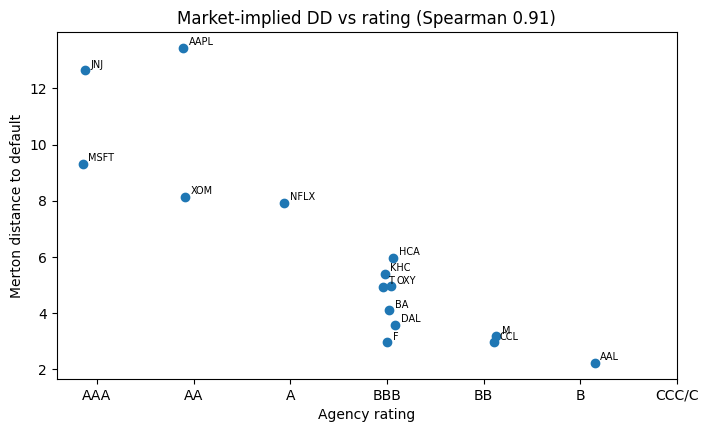

In [17]:
jitter = np.linspace(-0.15, 0.15, len(table))           # spread overlapping points sideways
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(table["rank"] + jitter, table["DD"])
for (t, row), j in zip(table.iterrows(), jitter):
    ax.annotate(t, (row["rank"] + j, row["DD"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.set_xticks(range(len(RATINGS)), RATINGS)
ax.set(xlabel="Agency rating", ylabel="Merton distance to default",
       title=f"Market-implied DD vs rating (Spearman {rho:.2f})")
fig.savefig(ROOT / "reports" / "figures" / "merton_dd_vs_rating.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the result:** DD falls as ratings fall. Within one grade the spread is wide — among BBB issuers DD runs from about 3 (Ford) to 6 (HCA). Merton separates firms that a rating puts in the same bucket, which is its value as an early-warning signal.

## 6. Distance to default through 2020 stress for the universe

Re-run the model at every month-end from January 2019 to December 2021, using **only information available on that date**.

$$D_t = \text{default point from the latest 10-K / 10-Q filed on or before } t$$

No look-ahead: a balance sheet counts only once it has actually been filed.

$$E_t = E_{\text{today}} \times \frac{P_t}{P_{\text{today}}}$$

Equity moves with the share price; the share count is held at today's value, which keeps stock splits consistent.

$$\sigma_{E,t} = \text{volatility of the 252 daily returns up to } t, \qquad r_t = \text{1-year Treasury on date } t$$

**Limitation:** firms that issued many new shares in 2020 (cruise lines, airlines) get too much equity before the issue, so their 2020 fall in DD is understated.

### 6.1 Balance sheet as known on a past date (no look-ahead)

The key line is `filed <= date`: e.g. Ford's year-end 2019 balance sheet only counts from its filing in February 2020.

In [18]:
def fact_asof(facts, tags, date):
    # Latest USD value among `tags` from 10-K / 10-Q filings FILED on or before `date`
    for tag in tags:
        items = facts["facts"]["us-gaap"].get(tag, {}).get("units", {}).get("USD", [])
        items = [i for i in items if i.get("form") in ("10-K", "10-Q") and i["filed"] <= date]
        if items:
            return float(max(items, key=lambda i: (i["end"], i["filed"]))["val"])
    return np.nan

def default_point_asof(facts, date):
    cur_t = fact_asof(facts, ["LiabilitiesCurrent"], date)
    tot_t = fact_asof(facts, ["Liabilities"], date)
    if np.isnan(tot_t):   # some filers do not tag total liabilities
        tot_t = fact_asof(facts, ["Assets"], date) - fact_asof(facts, ["StockholdersEquity"], date)
    return cur_t + 0.5 * (tot_t - cur_t)

for day in ["2019-12-31", "2020-03-31", "2020-06-30"]:
    print(day, f"Ford D = ${default_point_asof(facts, day) / 1e9:.1f}bn")

2019-12-31 Ford D = $160.9bn
2020-03-31 Ford D = $161.7bn
2020-06-30 Ford D = $164.5bn


**Reading the result:** Ford's default point barely moves (USD 161–165bn), so in 2020 the stress comes from equity value and volatility, not from new debt.

### 6.2 Monthly distance to default for one issuer

In [19]:
def dd_history(ticker, dates):
    facts_i, px = load_facts(ticker), load_prices(ticker)
    E_now = merton_inputs(ticker, r)["E"]                         # today's equity value
    vol = np.log(px).diff().rolling(WINDOW).std() * np.sqrt(252)  # trailing 252-day vol, each day
    rows = []
    for t in dates:
        E_t = E_now * px.loc[:t].iloc[-1] / px.iloc[-1]           # equity scaled by price ratio
        s_t, r_t = vol.loc[:t].iloc[-1], rates.loc[:t].iloc[-1] / 100
        D_t = default_point_asof(facts_i, t.strftime("%Y-%m-%d"))
        V_t, sV_t = solve_assets(E_t, s_t, D_t, r_t, T)
        dd_t = distance_to_default(V_t, D_t, r_t, sV_t, T)
        rows.append({"ticker": ticker, "date": t, "E": E_t, "sigma_E": s_t, "D": D_t, "r": r_t,
                     "V": V_t, "sigma_V": sV_t, "DD": dd_t, "PD": norm.cdf(-dd_t)})
    return rows

months = pd.date_range("2019-01-31", "2021-12-31", freq="BME")    # business month-ends
ford = pd.DataFrame(dd_history(EXAMPLE, months)).set_index("date")
ford.loc[["2019-12-31", "2020-03-31", "2020-06-30", "2021-12-31"], ["E", "sigma_E", "D", "DD"]]

,E,sigma_E,D,DD
date,,,,
2019-12-31,"37,116,300,761.223",0.274,"160,928,500,000.000",4.014
2020-03-31,"19,276,529,695.511",0.436,"161,719,500,000.000",2.378
2020-06-30,"24,265,279,695.511",0.530,"164,473,000,000.000",1.931
2021-12-31,"82,893,071,826.935",0.414,"152,503,000,000.000",2.906


**Reading the result:** Ford's DD falls from 4.0 (Dec 2019) to 2.4 (Mar 2020) and bottoms at 1.9 (Jun 2020) — S&P cut Ford below investment grade in March 2020. The low comes three months after the crash because the 252-day volatility window keeps adding crash days.

### 6.3 Monthly panel for all 15 issuers, 2019–2021

In [20]:
panel = pd.DataFrame([row for t in UNIVERSE for row in dd_history(t, months)])
(DATA / "processed").mkdir(parents=True, exist_ok=True)
panel.to_parquet(DATA / "processed" / "merton_dd_panel.parquet", index=False)

dd_wide = panel.pivot(index="date", columns="ticker", values="DD")
dd_wide.loc[pd.to_datetime(["2019-12-31", "2020-03-31", "2020-06-30", "2021-12-31"])].T.sort_values(pd.Timestamp("2020-06-30"))

,2019-12-31,2020-03-31,2020-06-30,2021-12-31
ticker,,,,
OXY,4.330,0.768,0.519,2.215
AAL,3.329,1.370,0.757,2.311
CCL,7.529,1.505,0.889,2.635
M,2.681,1.443,0.911,1.717
DAL,6.072,2.017,1.396,3.262
BA,6.332,2.031,1.423,4.019
F,4.014,2.378,1.931,2.906
HCA,5.331,2.512,2.162,6.148
KHC,3.293,3.014,3.030,7.064


**Reading the result:** every issuer's DD fell in 2020. Hardest hit: OXY (oil price crash on top of acquisition debt, 4.3 → 0.5), CCL (7.5 → 0.9) and AAL (3.3 → 0.8). Consumer staples KHC barely moved. By end-2021 most issuers are back at or above their 2019 level — Merton reacts within the cycle in both directions; ratings move much more slowly.

### 6.4 Figure: distance to default through 2019–2021, recession shaded

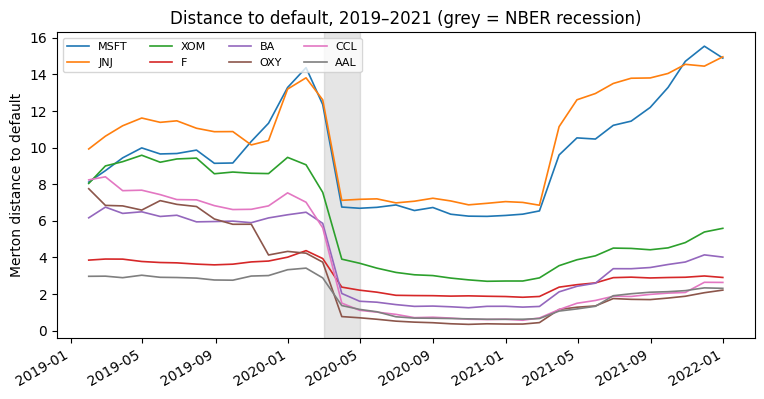

In [21]:
recession = load_fred("macro", "USREC").loc["2019":"2021"]
rec_months = recession[recession > 0].index
fig, ax = plt.subplots(figsize=(9, 4.5))
dd_wide[["MSFT", "JNJ", "XOM", "F", "BA", "OXY", "CCL", "AAL"]].plot(ax=ax, lw=1.2, x_compat=True)
ax.axvspan(rec_months[0], rec_months[-1] + pd.offsets.MonthEnd(1), color="grey", alpha=0.2)
ax.set(xlabel="", ylabel="Merton distance to default",
       title="Distance to default, 2019–2021 (grey = NBER recession)")
ax.legend(ncol=4, fontsize=8)
fig.savefig(ROOT / "reports" / "figures" / "merton_dd_2020.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the result:** all issuers fall together inside the recession band and stay low for a year. The jump in **March 2021** is not news about the firms — it is the day the March 2020 crash days leave the 252-day volatility window. A faster volatility measure (exponentially weighted) would avoid both the late low and the step back up.

## Validation checks

- [x] **Solver converges for every firm-date** — plugging $(V, \sigma_V)$ back into Black–Scholes reproduces $E$ and $\sigma_E$ within one part in a million, today and for every month 2019–2021.
- [x] **PD ordering broadly consistent with ratings** — Spearman rank correlation of DD with rating above 0.5.
- [x] **Sensitivity of PD to default-point choice** — PD rises as $D$ moves from current liabilities → KMV → total liabilities.

In [22]:
E_chk, se_chk = equity_from_assets(panel["V"], panel["sigma_V"], panel["D"], panel["r"], T)
checks = {
    "Solver converges for every firm (latest date)": bool(table["converged"].all()),
    "Solver converges for every firm-date (2019-21 panel)":
        bool(np.allclose(E_chk, panel["E"], rtol=1e-6) and np.allclose(se_chk, panel["sigma_E"], rtol=1e-6)),
    "PD ordering consistent with ratings (Spearman > 0.5)": bool(rho > 0.5),
    "PD rises as the default point rises": bool(sens["PD %"].is_monotonic_increasing),
}
pd.Series(checks).map({True: "PASS", False: "FAIL"})

Solver converges for every firm (latest date)           PASS
Solver converges for every firm-date (2019-21 panel)    PASS
PD ordering consistent with ratings (Spearman > 0.5)    PASS
PD rises as the default point rises                     PASS
dtype: object

## Functions to move into the engine

| Function (this notebook) | Target module | Test |
|---|---|---|
| `equity_from_assets` | `creditengine.models.merton` | solve, re-price, recover $E$ and $\sigma_E$ |
| `solve_assets` (method 1) | `creditengine.models.merton` | round trip within 1e-6 |
| `solve_assets_iterative` (KMV, method 2) | `creditengine.models.merton` — **new** | $\sigma_V$ close to method 1 |
| `distance_to_default`, $PD = N(-DD)$ | `creditengine.models.merton` | hand example: $V$=100, $D$=80, $\mu$=5%, $\sigma_V$=20% → DD = 1.266 |
| `load_prices`, `load_facts`, `latest_fact`, `merton_inputs` | `creditengine.data.edgar` | reproduces Ford inputs (2.5 = 4.3) |
| `shares_outstanding` (newest of three tags) | `creditengine.data.edgar` — **fix** | Ford gives a 2026 count, not 2011 |
| `load_fred` | `creditengine.data.fred` | latest DGS1 value |
| `fact_asof`, `default_point_asof`, `dd_history` | `creditengine.data.edgar`, `models.merton` — **new** | no look-ahead: only filings filed on or before $t$ |

**new** = added in this notebook, not yet in the engine. **fix** = this notebook found and corrected a weakness in the engine's version.

## Findings and next steps

**Key results**
- **Ford:** assets USD 216.7bn, asset volatility 8.4%, default point / assets 0.81 → DD 2.97, PD 0.15% (rating-implied BBB: 0.14%).
- **Model risk — solver:** the iterative KMV method gives asset volatility 9.2% → PD 0.33%, about twice method 1.
- **Model risk — default point:** PD 0.08% (current liabilities) → 0.15% (KMV) → 0.20% (total liabilities).
- **Ranking:** Spearman 0.91 between DD and rating across 15 issuers; every solve converged.
- **Levels:** Merton PD is below rating PD for nearly every issuer; 9 of 15 are about 0%.
- **2020 stress:** every issuer's DD fell; largest falls CCL 7.5 → 0.9, OXY 4.3 → 0.5, AAL 3.3 → 0.8; KHC barely moved.

**Assumptions** (record in `docs/assumption_register.md`)
- A-12 unchanged: KMV default point, 1-year horizon, 1-year Treasury rate, 252-day equity volatility.
- Added: asset drift $\mu = r$ (risk-neutral, conservative); share count = newest of three SEC tags.

**Limitations** (record in `docs/limitations.md`)
1. **Listed issuers only.** Merton needs a traded share price; private and specialty-finance credits need a rating- or financials-based PD (NB04).
2. **Finance arms.** Consolidated lenders such as Ford Credit inflate the default point.
3. **No sudden jumps.** Asset value moves smoothly in the model, so safe firms get PDs near zero; rankings are more reliable than levels.
4. **Slow volatility window.** The 252-day window puts the low three months after the crash and causes a step up a year later; an exponentially weighted volatility would react faster.
5. **Share count held fixed in section 6**, which understates the 2020 stress for firms that raised new equity (CCL, AAL).

**Data finding:** the SEC cover-page share count for Ford stops in 2011; fixed here by taking the newest of three share counts — apply the same fix in the engine loader.

**Next:** NB01 (data foundation), then NB04 (rating migration and thresholds).